ERK Biosensor Analysis Pipeline
  Data file       : ALL CONC.csv
  Frame interval  : 1 min
  Smooth window   : 6 frames
  Prominence      : 0.057
  FWHM rel_height : 0.55  (55%)

Loaded: 100 cells × 151 timepoints
  fifty: 25 cells
  five: 24 cells
  five hundred: 26 cells
  zero: 25 cells

Groups: ['five hundred', 'fifty', 'five', 'zero']

Analysing cells...

Per-cell results → erk_results.csv

  Cell

  [five hundred]
five hundred_cell1
five hundred_cell2
five hundred_cell3
five hundred_cell4
five hundred_cell5
five hundred_cell6
five hundred_cell7
five hundred_cell8
five hundred_cell9
five hundred_cell10
five hundred_cell11
five hundred_cell12
five hundred_cell13
five hundred_cell14
five hundred_cell15
five hundred_cell16
five hundred_cell17
five hundred_cell18
five hundred_cell19
five hundred_cell20
five hundred_cell21
five hundred_cell22
five hundred_cell23
five hundred_cell24
five hundred_cell25
five hundred_cell26

  [fifty]
fifty_cell27
fifty_cell28
fifty_cell29
fifty_cell30
fi

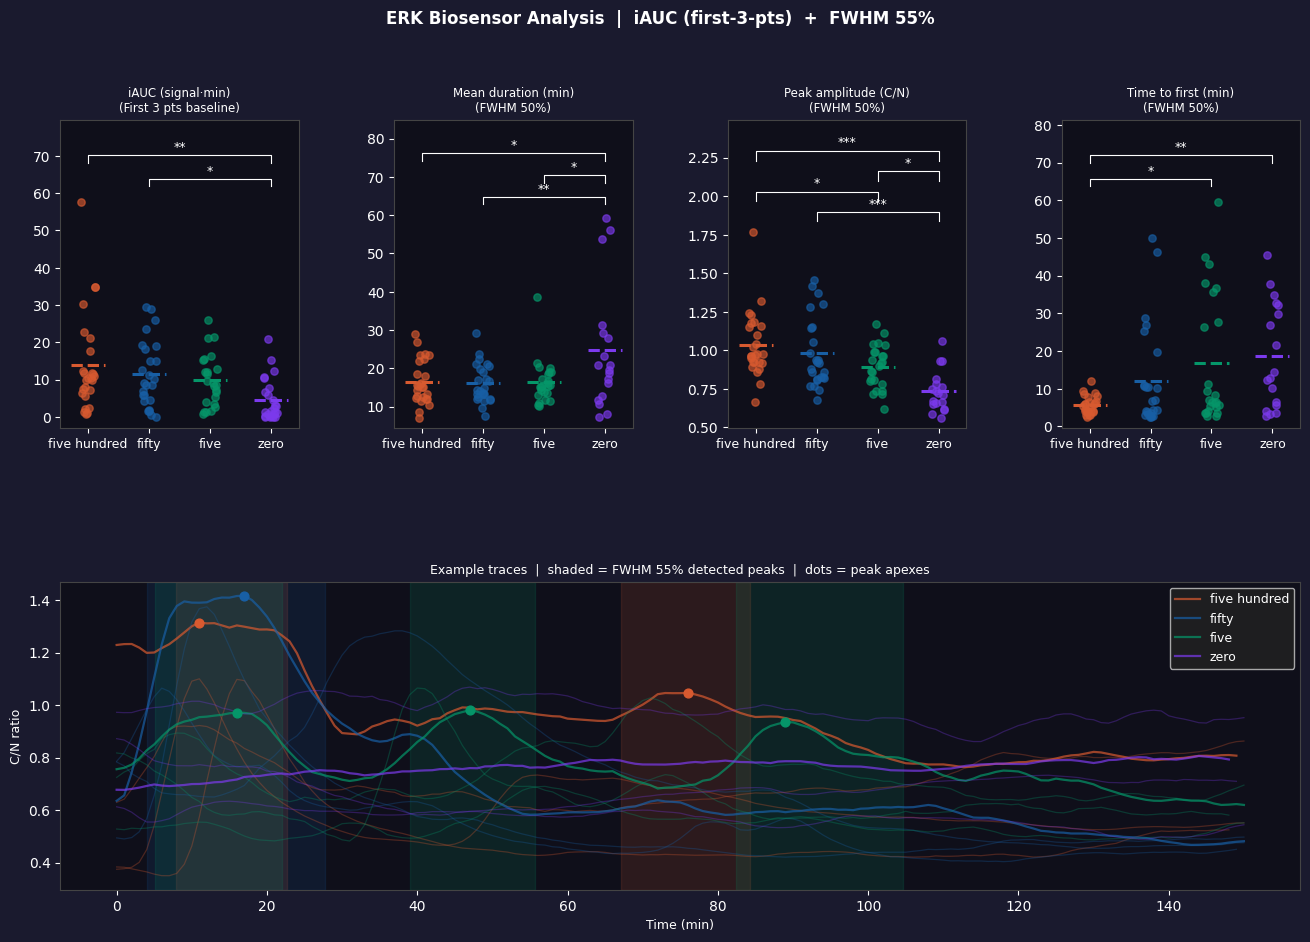


Done.


In [ ]:
"""
ERK Biosensor Trace Analysis Pipeline
======================================
Paste your data as tab-separated columns (one cell per column, one timepoint
per row). The header row contains condition labels (e.g. KO, NT).
Blank cells are treated as missing data (NaN).

METRICS COMPUTED:
  iAUC       — integrated area above first-3-points baseline  [First 3 pts method]
  Duration   — mean peak duration (FWHM at 50%)               [FWHM 50% method]
  Amplitude  — mean peak apex C/N ratio                       [FWHM 50% method]
  TTF        — time to first peak onset                       [FWHM 50% method]

STATISTICS:
  2 groups, equal n    — paired t-test (two-sided)
  2 groups, unequal n  — Welch's t-test (two-sided, unequal variance assumed)
  >2 groups            — one-way ANOVA omnibus → Tukey HSD post-hoc (all pairwise)

USAGE:
  1. Save your data as a .csv file with conditions in the header row
  2. Edit the USER SETTINGS below if needed
  3. Run:   python erk_analysis.py
  4. Check: erk_results.csv   (per-cell)
            erk_summary.csv   (group means ± SEM + p-values)
            Figure displayed in output window
"""

import numpy as np
import pandas as pd
import itertools
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks, peak_widths
from scipy.stats import ttest_rel, ttest_ind, f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings, sys, os
warnings.filterwarnings('ignore')

# ══════════════════════════════════════════════════════════════════════════════
#  USER SETTINGS #updated 20260814
# ══════════════════════════════════════════════════════════════════════════════

DATA_FILE          = "ALL CONC.csv"   # .tsv or .csv; first row = condition labels
FRAME_INTERVAL_MIN = 1                # minutes per frame
SMOOTH_WINDOW      = 6                # smoothing window in frames (set 1 to skip)
PROMINENCE         = 0.057            # minimum peak prominence for detection
MIN_PEAK_DIST      = 3                # minimum frames between two peaks
FWHM_REL_HEIGHT    = 0.55             # 0.5 = classic FWHM | 0.9 = full-width near base, set 0.55 as a small adjustment for shoulder noise
OUTPUT_PREFIX      = "erk"            # prefix for all output files

# Which groups to compare statistically.
# Set to None to auto-detect from header, or e.g. ["KO", "NT"]
COMPARE_GROUPS     = None

# ══════════════════════════════════════════════════════════════════════════════
#  DATA LOADING
# ══════════════════════════════════════════════════════════════════════════════

def load_data(path):
    """
    Load TSV/CSV. First row = condition labels. Returns (conditions, matrix).
    Handles duplicate column names (multiple cells with same condition label).
    """
    sep = '\t' if path.endswith('.tsv') else ','
    with open(path) as f:
        lines = f.readlines()

    if len(lines) < 2:
        print("ERROR: file has fewer than 2 rows."); sys.exit(1)

    conditions = [c.strip() for c in lines[0].rstrip('\n').split(sep)]
    n_cols = len(conditions)

    rows = []
    for line in lines[1:]:
        vals = line.rstrip('\n').split(sep)
        while len(vals) < n_cols:
            vals.append('')
        row = []
        for v in vals[:n_cols]:
            try:    row.append(float(v.strip()))
            except: row.append(np.nan)
        rows.append(row)

    data = np.array(rows, dtype=float)
    print(f"\nLoaded: {data.shape[1]} cells × {data.shape[0]} timepoints")
    from collections import Counter
    for cond, n in sorted(Counter(conditions).items()):
        print(f"  {cond}: {n} cells")
    return conditions, data

# ══════════════════════════════════════════════════════════════════════════════
#  PREPROCESSING
# ══════════════════════════════════════════════════════════════════════════════

def prep_trace(raw):
    """Trim NaN edges, interpolate internal NaNs, smooth."""
    valid = np.where(~np.isnan(raw))[0]
    if len(valid) < 10:
        return None
    t = raw[valid[0]:valid[-1]+1].copy()
    nans = np.isnan(t)
    if nans.any():
        x = np.arange(len(t))
        t = np.interp(x, x[~nans], t[~nans])
    if SMOOTH_WINDOW > 1:
        t = uniform_filter1d(t.astype(float), size=SMOOTH_WINDOW)
    return t

# ══════════════════════════════════════════════════════════════════════════════
#  METRIC 1 — iAUC  (first-3-points baseline)
# ══════════════════════════════════════════════════════════════════════════════

def compute_iauc(t):
    """
    baseline = mean of first 3 smoothed timepoints
    iAUC     = Σ max(0, signal − baseline) × frame_interval_min
    """
    baseline = float(np.mean(t[:3]))
    iauc = float(np.sum(np.maximum(0.0, t - baseline))) * FRAME_INTERVAL_MIN
    return iauc, baseline

# ══════════════════════════════════════════════════════════════════════════════
#  METRICS 2–4 — Duration, Amplitude, TTF  (FWHM 50%)
# ══════════════════════════════════════════════════════════════════════════════

def compute_fwhm_metrics(t):
    """
    Detect peaks by prominence, measure width at FWHM_REL_HEIGHT.

    TTF       = time of first peak's left FWHM edge (onset), in minutes
    Duration  = mean width across all detected peaks, in minutes
    Amplitude = mean apex C/N ratio across all detected peaks
    """
    pks, _ = find_peaks(t, prominence=PROMINENCE, distance=MIN_PEAK_DIST)

    if len(pks) == 0:
        return dict(n_peaks=0, ttf=None, mean_dur=None, mean_amp=None,
                    peaks=[], wl=[], wr=[], wh=[])

    widths, wh, wl, wr = peak_widths(t, pks, rel_height=FWHM_REL_HEIGHT)

    return dict(
        n_peaks  = len(pks),
        ttf      = float(wl[0]) * FRAME_INTERVAL_MIN,
        mean_dur = float(np.mean(widths)) * FRAME_INTERVAL_MIN,
        mean_amp = float(np.mean([t[p] for p in pks])),
        peaks    = pks.tolist(),
        wl       = wl.tolist(),
        wr       = wr.tolist(),
        wh       = wh.tolist(),
    )

# ══════════════════════════════════════════════════════════════════════════════
#  ANALYSE ALL CELLS
# ══════════════════════════════════════════════════════════════════════════════

def analyse_all(conditions, data):
    records = []
    for idx, cond in enumerate(conditions):
        t = prep_trace(data[:, idx])
        cell_id = f"{cond}_cell{idx+1}"

        if t is None:
            print(f"  WARNING: {cell_id} skipped (insufficient data).")
            records.append(dict(cell=cell_id, condition=cond,
                                n_valid_frames=0, n_peaks=0,
                                iauc=np.nan, baseline_first3=np.nan,
                                ttf_min=np.nan, mean_dur_min=np.nan,
                                mean_amp=np.nan))
            continue

        iauc_val, baseline = compute_iauc(t)
        fwhm = compute_fwhm_metrics(t)

        records.append(dict(
            cell            = cell_id,
            condition       = cond,
            n_valid_frames  = len(t),
            n_peaks         = fwhm['n_peaks'],
            iauc            = round(iauc_val, 4),
            baseline_first3 = round(baseline, 4),
            ttf_min         = round(fwhm['ttf'], 2)      if fwhm['ttf']      is not None else np.nan,
            mean_dur_min    = round(fwhm['mean_dur'], 2)  if fwhm['mean_dur'] is not None else np.nan,
            mean_amp        = round(fwhm['mean_amp'], 4)  if fwhm['mean_amp'] is not None else np.nan,
        ))

    return pd.DataFrame(records)

# ══════════════════════════════════════════════════════════════════════════════
#  GROUP SUMMARY + STATISTICS
# ══════════════════════════════════════════════════════════════════════════════

METRIC_DEFS = [
    ('iauc',         'iAUC (signal·min)',    'First 3 pts baseline'),
    ('mean_dur_min', 'Mean duration (min)',   'FWHM 50%'),
    ('mean_amp',     'Peak amplitude (C/N)', 'FWHM 50%'),
    ('ttf_min',      'Time to first (min)',  'FWHM 50%'),
]

def _sig_label(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'


def _run_anova_tukey(df, groups, col):
    """
    One-way ANOVA omnibus across all groups, then Tukey HSD post-hoc.
    Returns:
        F, anova_p  — omnibus statistics
        pairs       — list of (g1, g2, p_tukey, sig_label)
    """
    arrays = [df.loc[df['condition'] == g, col].dropna().values for g in groups]
    valid  = [(g, a) for g, a in zip(groups, arrays) if len(a) >= 2]
    if len(valid) < 2:
        return None, None, []

    valid_groups, valid_arrays = zip(*valid)
    F, anova_p = f_oneway(*valid_arrays)

    # Tukey HSD on all observations with group labels
    all_vals   = np.concatenate(valid_arrays)
    all_labels = np.concatenate([[g] * len(a) for g, a in zip(valid_groups, valid_arrays)])
    tukey      = pairwise_tukeyhsd(all_vals, all_labels, alpha=0.05)
    tukey_df   = pd.DataFrame(
        data  = tukey._results_table.data[1:],
        columns = tukey._results_table.data[0]
    )

    pairs = []
    for _, row in tukey_df.iterrows():
        g1, g2   = str(row['group1']), str(row['group2'])
        p_tukey  = float(row['p-adj'])
        pairs.append((g1, g2, p_tukey, _sig_label(p_tukey)))

    return float(F), float(anova_p), pairs


# Module-level cache so plot_results() can read post-hoc results
_POSTHOC_CACHE = {}


def _two_group_test(av, bv):
    """
    Select and run the appropriate two-group test:
      - Equal n   → paired t-test (ttest_rel)
      - Unequal n → Welch's t-test (ttest_ind, equal_var=False)
    Returns (p, test_name).
    """
    if len(av) == len(bv):
        _, p = ttest_rel(av, bv)
        test_name = "paired t-test"
    else:
        _, p = ttest_ind(av, bv, equal_var=False)
        test_name = f"Welch's t-test (n={len(av)} vs {len(bv)})"
    return p, test_name


def summarise(df, groups):
    global _POSTHOC_CACHE
    _POSTHOC_CACHE = {}

    rows = []
    for col, label, method in METRIC_DEFS:
        for g in groups:
            vals = df.loc[df['condition'] == g, col].dropna().values
            rows.append(dict(
                metric    = label,
                method    = method,
                condition = g,
                n         = len(vals),
                mean      = round(float(np.mean(vals)),   3) if len(vals)   else np.nan,
                median    = round(float(np.median(vals)), 3) if len(vals)   else np.nan,
                sd        = round(float(np.std(vals, ddof=1)), 3)                       if len(vals) > 1 else np.nan,
                sem       = round(float(np.std(vals, ddof=1) / np.sqrt(len(vals))), 3) if len(vals) > 1 else np.nan,
            ))

    sum_df = pd.DataFrame(rows)

    # ── 2 groups: paired t-test or Welch's t-test ─────────────────────────
    if len(groups) == 2:
        print(f"\n{'Metric':<25} {'Method':<20} {groups[0]:>8} {groups[1]:>8} {'Δ%':>7}  {'p':>8}  sig  test")
        print(f"  (paired t-test when n equal; Welch's t-test when n unequal, two-sided)")
        print('─' * 95)
        for col, label, method in METRIC_DEFS:
            av = df.loc[df['condition'] == groups[0], col].dropna().values
            bv = df.loc[df['condition'] == groups[1], col].dropna().values
            if len(av) > 1 and len(bv) > 1:
                p, test_name = _two_group_test(av, bv)
                am, bm = np.mean(av), np.mean(bv)
                pct = (am - bm) / bm * 100 if bm else 0
                sig = _sig_label(p)
                print(f"{label:<25} {method:<20} {am:>8.3f} {bm:>8.3f} {pct:>+7.1f}%  {p:>8.4f}  {sig:<3}  [{test_name}]")
            else:
                print(f"{label:<25} {method:<20} {'—':>8} {'—':>8} {'—':>7}  {'—':>8}  —")

    # ── >2 groups: one-way ANOVA + Tukey HSD ──────────────────────────────
    elif len(groups) > 2:
        print(f"\n{'─' * 80}")
        print(f"  Multi-group test: one-way ANOVA omnibus → Tukey HSD post-hoc")
        print(f"  Groups: {groups}")
        print(f"{'─' * 80}")

        for col, label, method in METRIC_DEFS:
            F, anova_p, pairs = _run_anova_tukey(df, groups, col)
            _POSTHOC_CACHE[col] = pairs   # store for plot_results()

            if F is None:
                print(f"\n  {label}: insufficient data for ANOVA")
                continue

            anova_sig = _sig_label(anova_p)
            means_str = "  |  ".join(
                f"{g}: {df.loc[df['condition'] == g, col].dropna().mean():.3f}"
                for g in groups
            )
            print(f"\n  {label}  [{method}]")
            print(f"    One-way ANOVA  F={F:.3f}  p={anova_p:.4f}  {anova_sig}")
            print(f"    Means — {means_str}")
            print(f"    Tukey HSD post-hoc:")
            for g1, g2, p_tukey, sig in pairs:
                print(f"      {g1} vs {g2}:  p_adj={p_tukey:.4f}  {sig}")

        print(f"\n{'─' * 80}")

    return sum_df

# ══════════════════════════════════════════════════════════════════════════════
#  FIGURES
# ══════════════════════════════════════════════════════════════════════════════

PALETTE = ['#D85A30', '#185FA5', '#059669', '#7c3aed', '#d97706', '#dc2626']

def plot_results(df, groups, conditions, data):
    colors = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(groups)}

    n_metrics = len(METRIC_DEFS)
    fig = plt.figure(figsize=(4 * n_metrics, 10))
    fig.patch.set_facecolor('#1a1a2e')
    gs = gridspec.GridSpec(2, n_metrics, figure=fig, hspace=0.5, wspace=0.4)

    # ── row 1: dot plots ──
    for mi, (col, label, method) in enumerate(METRIC_DEFS):
        ax = fig.add_subplot(gs[0, mi])
        ax.set_facecolor('#0f0f1a')
        np.random.seed(42)

        for gi, g in enumerate(groups):
            vals = df.loc[df['condition'] == g, col].dropna().values
            x = np.ones(len(vals)) * (gi + 1) + np.random.uniform(-0.12, 0.12, len(vals))
            ax.scatter(x, vals, color=colors[g], alpha=0.65, s=28, zorder=3)
            if len(vals):
                ax.hlines(np.mean(vals), gi + 0.72, gi + 1.28,
                          color=colors[g], lw=2.2, linestyle='--')

        # ── significance annotation ──────────────────────────────────────
        if len(groups) == 2:
            av = df.loc[df['condition'] == groups[0], col].dropna().values
            bv = df.loc[df['condition'] == groups[1], col].dropna().values
            if len(av) > 1 and len(bv) > 1:
                p, _ = _two_group_test(av, bv)
                sig = _sig_label(p)
                cur_max = ax.get_ylim()[1]
                ax.set_ylim(top=cur_max * 1.18)
                y_br = ax.get_ylim()[1] * 0.96
                ax.plot([1, 1, 2, 2], [y_br * 0.96, y_br, y_br, y_br * 0.96],
                        color='white', lw=0.8)
                ax.text(1.5, y_br * 1.01, sig, ha='center', va='bottom',
                        color='white', fontsize=10)

        elif len(groups) > 2:
            # Draw Tukey brackets only for significant pairs (p < 0.05)
            pairs = _POSTHOC_CACHE.get(col, [])
            sig_pairs = [(g1, g2, sig) for g1, g2, p_tukey, sig in pairs if p_tukey < 0.05]

            if sig_pairs:
                y_min, cur_top = ax.get_ylim()
                step = (cur_top - y_min) * 0.10
                ax.set_ylim(top=cur_top + step * (len(sig_pairs) + 1))
                g_pos = {g: i + 1 for i, g in enumerate(groups)}
                y_base = cur_top + step * 0.5

                for k, (g1, g2, sig) in enumerate(sig_pairs):
                    x1, x2 = g_pos.get(g1, 1), g_pos.get(g2, 2)
                    y = y_base + step * k
                    ax.plot([x1, x1, x2, x2], [y * 0.97, y, y, y * 0.97],
                            color='white', lw=0.8)
                    ax.text((x1 + x2) / 2, y * 1.005, sig,
                            ha='center', va='bottom', color='white', fontsize=9)
        # ─────────────────────────────────────────────────────────────────

        ax.set_title(f"{label}\n({method})", color='white', fontsize=8.5)
        ax.set_xticks(range(1, len(groups) + 1))
        ax.set_xticklabels(groups, color='white', fontsize=9)
        ax.tick_params(colors='white')
        for sp in ax.spines.values(): sp.set_edgecolor('#444')

    # ── row 2: example traces (first 4 per group) ──
    ax_t = fig.add_subplot(gs[1, :])
    ax_t.set_facecolor('#0f0f1a')
    plotted = {g: 0 for g in groups}
    max_per = 4

    for ci, cond in enumerate(conditions):
        if cond not in groups or plotted[cond] >= max_per:
            continue
        t = prep_trace(data[:, ci])
        if t is None: continue
        t_time = np.arange(len(t)) * FRAME_INTERVAL_MIN
        first = (plotted[cond] == 0)
        ax_t.plot(t_time, t, color=colors[cond], alpha=0.7 if first else 0.3,
                  lw=1.6 if first else 0.9,
                  label=cond if first else None)

        if first:
            fm = compute_fwhm_metrics(t)
            for pi, pk in enumerate(fm['peaks']):
                ax_t.axvspan(fm['wl'][pi] * FRAME_INTERVAL_MIN,
                             fm['wr'][pi] * FRAME_INTERVAL_MIN,
                             alpha=0.15, color=colors[cond])
                ax_t.scatter([pk * FRAME_INTERVAL_MIN], [t[pk]],
                             color=colors[cond], s=40, zorder=5)
        plotted[cond] += 1

    ax_t.legend(fontsize=9, facecolor='#222', labelcolor='white',
                loc='upper right', framealpha=0.8)
    ax_t.set_title(
        f'Example traces  |  shaded = FWHM {int(FWHM_REL_HEIGHT*100)}% detected peaks  |  dots = peak apexes',
        color='white', fontsize=9)
    ax_t.set_xlabel('Time (min)', color='white', fontsize=9)
    ax_t.set_ylabel('C/N ratio', color='white', fontsize=9)
    ax_t.tick_params(colors='white')
    for sp in ax_t.spines.values(): sp.set_edgecolor('#444')

    fig.suptitle(
        f'ERK Biosensor Analysis  |  iAUC (first-3-pts)  +  FWHM {int(FWHM_REL_HEIGHT*100)}%',
        color='white', fontsize=12, fontweight='bold', y=0.99)

    plt.tight_layout()
    from IPython.display import display
    display(fig)
    plt.close(fig)

# ══════════════════════════════════════════════════════════════════════════════
#  MAIN
# ══════════════════════════════════════════════════════════════════════════════

def main():
    print("=" * 60)
    print("ERK Biosensor Analysis Pipeline")
    print(f"  Data file       : {DATA_FILE}")
    print(f"  Frame interval  : {FRAME_INTERVAL_MIN} min")
    print(f"  Smooth window   : {SMOOTH_WINDOW} frames")
    print(f"  Prominence      : {PROMINENCE}")
    print(f"  FWHM rel_height : {FWHM_REL_HEIGHT}  ({int(FWHM_REL_HEIGHT*100)}%)")
    print("=" * 60)

    if not os.path.exists(DATA_FILE):
        print(f"\nERROR: '{DATA_FILE}' not found.")
        print("Place your data file in the same folder as this script.")
        print("\nExpected format (tab-separated, .tsv):")
        print("  KO\\tKO\\tNT\\tNT         ← header: one label per cell")
        print("  0.82\\t0.79\\t0.71\\t0.68   ← timepoint 1")
        print("  0.85\\t0.81\\t0.72\\t0.70   ← timepoint 2")
        print("  (blank cells allowed — treated as missing)")
        sys.exit(1)

    conditions, data = load_data(DATA_FILE)

    # auto-detect groups
    global COMPARE_GROUPS
    if COMPARE_GROUPS is None:
        seen, unique = set(), []
        for c in conditions:
            if c not in seen: seen.add(c); unique.append(c)
        COMPARE_GROUPS = unique

    print(f"\nGroups: {COMPARE_GROUPS}")

    # analyse
    print("\nAnalysing cells...")
    results = analyse_all(conditions, data)

    # per-cell CSV
    out_cells = f"{OUTPUT_PREFIX}_results.csv"
    results.to_csv(out_cells, index=False)
    print(f"\nPer-cell results → {out_cells}")
    # ── copy-paste friendly columns, split by group ────────────────────────
    col_defs = [
        ('cell',         'Cell'),
        ('n_peaks',      'N peaks'),
        ('iauc',         'iAUC'),
        ('ttf_min',      'TTF (min)'),
        ('mean_dur_min', 'Mean duration (min)'),
        ('mean_amp',     'Peak amplitude'),
    ]
    for col, label in col_defs:
        print(f"\n{'='*40}")
        print(f"  {label}")
        print(f"{'='*40}")
        for g in COMPARE_GROUPS:
            print(f"\n  [{g}]")
            grp = results[results['condition'] == g][col]
            for val in grp:
                if isinstance(val, float) and np.isnan(val):
                    print("")
                else:
                    print(val)
    # ───────────────────────────────────────────────────────────────────────

    # group summary
    n_groups = len(COMPARE_GROUPS)
    if n_groups == 2:
        print(f"\nGroup summary (paired t-test or Welch's t-test, auto-selected by n):")
    else:
        print(f"\nGroup summary (one-way ANOVA + Tukey HSD):")
    summary = summarise(results, COMPARE_GROUPS)
    out_sum = f"{OUTPUT_PREFIX}_summary.csv"
    summary.to_csv(out_sum, index=False)
    print(f"\nGroup summary → {out_sum}")

    # figures
    try:
        plot_results(results, COMPARE_GROUPS, conditions, data)
    except Exception as e:
        print(f"Figure warning: {e}")

    print("\nDone.")

if __name__ == "__main__":
    main()